# Station Recovery
*Sean Qin*

Which stations repeatedly have morning net departures, and how often do later net arrivals offset them?
As planned in the proposal, I compare recovery distributions and full-recovery rates across stations, plot cumulative hourly flows,
and check whether the results hold for deficits of at least five bikes and for different time windows.

Data: `station_day.csv` and `station_events.csv` from `01_data_cleaning.ipynb`.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

MORNING, LATER = (6, 10), (10, 20)


def recovery_summary(df, by):
    """Median recovery, full-recovery rate, and pooled recovery for each group in `by`."""
    out = df.groupby(by, observed=True).agg(
        station_days=("recovery", "count"),
        stations=("station_id", "nunique"),
        median_recovery=("recovery", "median"),
        full_recovery_rate=("full_recovery", "mean"),
        later_net=("later_net_arrivals", "sum"),
        morning_net=("morning_net_departures", "sum"),
    )
    out["pooled_recovery"] = out["later_net"] / out["morning_net"]
    return out.drop(columns=["later_net", "morning_net"]).round(3)

In [2]:
station_day = pd.read_csv(DATA / "station_day.csv")
events = pd.read_csv(DATA / "station_events.csv", usecols=["ride_id", "station_id", "event", "day", "hour"])
calendar = station_day.drop_duplicates("day")[["day", "day_type"]]
events = events.merge(calendar, on="day", how="left", validate="many_to_one")

deficit = station_day[station_day["has_morning_deficit"]].copy()
deficit["sample"] = "All deficit station-days"
print(f"{len(station_day):,} active station-days, {len(deficit):,} with a morning deficit")
recovery_summary(deficit, "sample")

30,383 active station-days, 11,408 with a morning deficit


,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
sample,,,,,
All deficit station-days,11408,1124,0.385,0.376,0.484


Across all 11,408 deficit station-days, the median station gets back about 38% of its morning loss by 8 p.m., and 38% fully recover. Pooled across all bikes, later net arrivals replace about 48% of morning net departures.

In [3]:
recovery_summary(deficit, "day_type")

,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
day_type,,,,,
Labor Day,290,290,0.0,0.390,0.230
Weekday,8548,1001,0.5,0.386,0.567
Weekend,2570,832,0.0,0.342,0.102


Weekday deficits recover more than weekend deficits, which fits commuters returning in the evening. Because of this, the rest of this notebook uses weekdays only; Mimi's question compares day types.

## Recurring morning deficits

A recurring-deficit station has a morning deficit on at least 15 of the 21 non-holiday weekdays (about 70%).

1,523 stations active on weekdays; 264 recurring-deficit stations


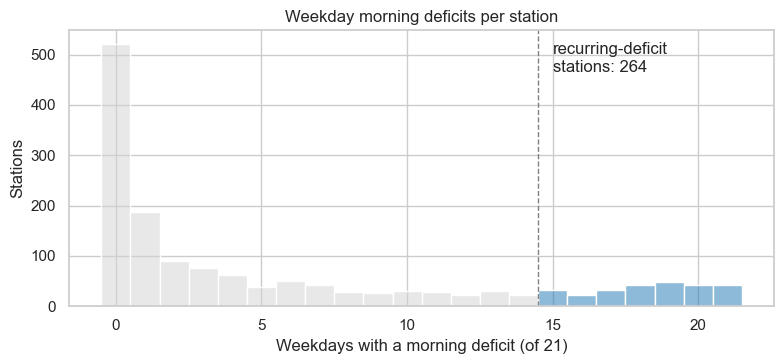

In [4]:
RECURRING_MIN_DAYS = 15
weekday = station_day[station_day["day_type"] == "Weekday"]
n_weekdays = weekday["day"].nunique()

per_station = weekday.groupby(["station_id", "station_name"]).agg(
    weekday_deficit_days=("has_morning_deficit", "sum"),
    mean_morning_net_dep=("morning_net_departures", "mean"),
).reset_index()
per_station["recurring"] = per_station["weekday_deficit_days"] >= RECURRING_MIN_DAYS
recurring_ids = per_station.loc[per_station["recurring"], "station_id"]
print(f"{len(per_station):,} stations active on weekdays; {len(recurring_ids)} recurring-deficit stations")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=per_station, x="weekday_deficit_days", hue="recurring", discrete=True,
             palette={False: "lightgray", True: "tab:blue"}, legend=False, ax=ax)
ax.axvline(RECURRING_MIN_DAYS - 0.5, color="gray", ls="--", lw=1)
ax.text(RECURRING_MIN_DAYS, ax.get_ylim()[1] * 0.85, f"recurring-deficit\nstations: {len(recurring_ids)}")
ax.set(xlabel=f"Weekdays with a morning deficit (of {n_weekdays})", ylabel="Stations",
       title="Weekday morning deficits per station")
fig.tight_layout()
fig.savefig(FIG / "sean_deficit_days_hist.png", dpi=200)
plt.show()

Most stations rarely start the day short, but there is a second bump at the high end: a group of stations with a deficit on most weekdays.

## Recovery at recurring-deficit stations

In [5]:
rec_days = deficit[deficit["station_id"].isin(recurring_ids) & (deficit["day_type"] == "Weekday")]
station_summary = recovery_summary(rec_days, ["station_id", "station_name"]).reset_index()
station_summary = station_summary.merge(per_station, on=["station_id", "station_name"], how="left", validate="one_to_one")

rec_days = rec_days.copy()
rec_days["sample"] = "Recurring stations, weekdays"
display(recovery_summary(rec_days, "sample"))

cols = ["station_name", "weekday_deficit_days", "mean_morning_net_dep",
        "median_recovery", "full_recovery_rate", "pooled_recovery"]
top_table = station_summary.sort_values("mean_morning_net_dep", ascending=False)[cols].head(15).round(2)
top_table.to_csv(FIG / "sean_top_deficit_stations.csv", index=False)
top_table

,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
sample,,,,,
"Recurring stations, weekdays",4838,264,0.625,0.394,0.62


,station_name,weekday_deficit_days,mean_morning_net_dep,median_recovery,full_recovery_rate,pooled_recovery
31,Clark St & Elm St,21,16.76,0.80,0.43,0.75
102,Indiana Ave & Roosevelt Rd,20,13.14,0.56,0.30,0.59
87,Clark St & Lincoln Ave,21,11.95,0.62,0.33,0.67
8,Loomis St & Lexington St,21,11.76,0.25,0.05,0.24
116,Clark St & Armitage Ave,21,11.24,0.86,0.48,0.84
196,Federal St & Polk St,20,10.05,0.66,0.45,0.56
159,Wabash Ave & 16th St,20,9.76,0.79,0.35,0.69
108,Clark St & Schiller St,21,9.14,0.77,0.43,0.78
161,Wells St & Polk St,21,8.29,0.85,0.43,0.71
122,Pine Grove Ave & Irving Park Rd,21,8.29,0.44,0.14,0.31


In [6]:
# Recovery by size of the typical morning deficit
station_summary["deficit_size"] = pd.qcut(station_summary["mean_morning_net_dep"], 3,
                                          labels=["Smaller deficits", "Middle", "Largest deficits"])
station_summary.groupby("deficit_size", observed=True).agg(
    stations=("station_id", "count"),
    mean_morning_net_dep=("mean_morning_net_dep", "mean"),
    median_full_recovery_rate=("full_recovery_rate", "median"),
    median_pooled_recovery=("pooled_recovery", "median"),
).round(2)

,stations,mean_morning_net_dep,median_full_recovery_rate,median_pooled_recovery
deficit_size,,,,
Smaller deficits,89,1.83,0.42,0.50
Middle,88,3.76,0.42,0.69
Largest deficits,87,6.72,0.38,0.69


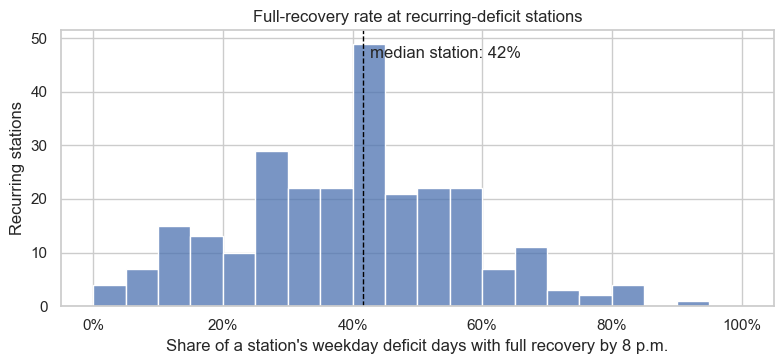

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=station_summary, x="full_recovery_rate", bins=np.linspace(0, 1, 21), ax=ax)
med = station_summary["full_recovery_rate"].median()
ax.axvline(med, color="black", ls="--", lw=1)
ax.text(med + 0.01, ax.get_ylim()[1] * 0.9, f"median station: {med:.0%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(xlabel="Share of a station's weekday deficit days with full recovery by 8 p.m.", ylabel="Recurring stations",
       title="Full-recovery rate at recurring-deficit stations")
fig.tight_layout()
fig.savefig(FIG / "sean_full_recovery_by_station.png", dpi=200)
plt.show()

## Hourly net flow through the day

For each recurring-deficit station, we add up net flow (arrivals − departures) hour by hour from 6 a.m. and average over weekdays. Stations are split into thirds by full-recovery rate.

In [8]:
ev = events[events["station_id"].isin(recurring_ids) & (events["day_type"] == "Weekday") & (events["hour"] >= 6)].copy()
ev["net"] = np.where(ev["event"] == "arrival", 1, -1)

hourly = ev.pivot_table(index=["station_id", "day"], columns="hour", values="net", aggfunc="sum").fillna(0)
cumulative = hourly.cumsum(axis=1)                          # running total since 6 a.m.
station_curves = cumulative.groupby("station_id").mean()    # average weekday curve per station

station_summary["tier"] = pd.qcut(station_summary["full_recovery_rate"], 3,
                                  labels=["Rarely recovers", "Sometimes recovers", "Usually recovers"])
display(station_summary.groupby("tier", observed=True)["full_recovery_rate"].agg(["count", "min", "max"]).round(2))

curves_long = station_curves.reset_index().melt(id_vars="station_id", var_name="hour", value_name="cum_net")
curves_long["hour_end"] = curves_long["hour"].astype(int) + 1   # value at the end of each hour
curves_long = curves_long.merge(station_summary[["station_id", "tier"]], on="station_id", how="left", validate="many_to_one")
curves_long.head()

,count,min,max
tier,,,
Rarely recovers,96,0.00,0.33
Sometimes recovers,80,0.35,0.47
Usually recovers,88,0.47,0.94


,station_id,hour,cum_net,hour_end,tier
0,CHI00005,6,-0.523810,7,Sometimes recovers
1,CHI00214,6,-1.285714,7,Sometimes recovers
2,CHI00217,6,-0.380952,7,Usually recovers
3,CHI00224,6,-0.380952,7,Rarely recovers
4,CHI00227,6,-0.285714,7,Rarely recovers


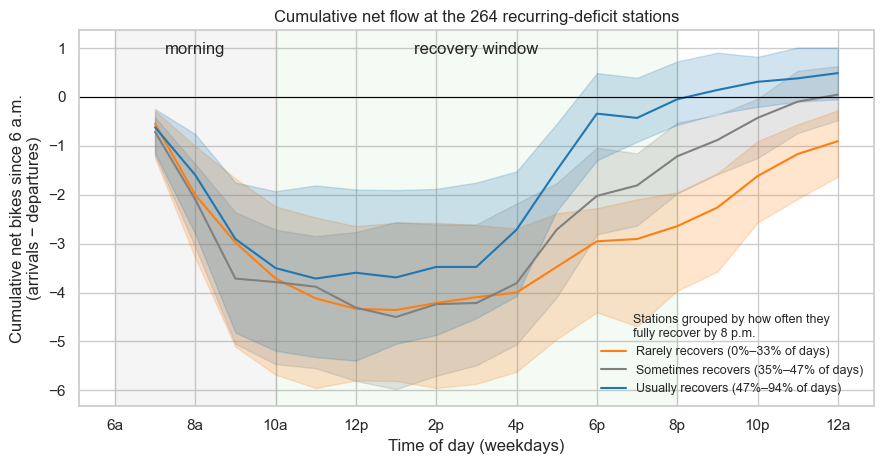

In [9]:
# Legend labels show each third's range of full-recovery rates
ranges = station_summary.groupby("tier", observed=True)["full_recovery_rate"].agg(["min", "max"])
labels = {t: f"{t} ({r['min']:.0%}–{r['max']:.0%} of days)" for t, r in ranges.iterrows()}
plot_data = curves_long.assign(tier=curves_long["tier"].map(labels))
colors = dict(zip(labels.values(), ["tab:orange", "gray", "tab:blue"]))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axvspan(*MORNING, color="gray", alpha=0.08)
ax.axvspan(*LATER, color="tab:green", alpha=0.05)
ax.text(8, 0.97, "morning", ha="center", va="top", transform=ax.get_xaxis_transform())
ax.text(15, 0.97, "recovery window", ha="center", va="top", transform=ax.get_xaxis_transform())
sns.lineplot(data=plot_data, x="hour_end", y="cum_net", hue="tier", palette=colors,
             estimator="median", errorbar=("pi", 50), ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([6, 8, 10, 12, 14, 16, 18, 20, 22, 24], ["6a", "8a", "10a", "12p", "2p", "4p", "6p", "8p", "10p", "12a"])
ax.set(xlabel="Time of day (weekdays)", ylabel="Cumulative net bikes since 6 a.m.\n(arrivals − departures)",
       title="Cumulative net flow at the 264 recurring-deficit stations")
ax.legend(title="Stations grouped by how often they\nfully recover by 8 p.m.", frameon=False, loc="lower right",
          fontsize=9, title_fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "sean_cumulative_hourly_flow.png", dpi=200)
plt.show()

The 264 recurring-deficit stations are split into thirds by the share of their deficit days that fully recover by 8 p.m. (legend). Lines are the median station in each third; bands cover the middle 50%. All three groups lose bikes at a similar rate until 10 a.m. After that, stations that usually recover climb back to around zero by late afternoon, while stations that rarely recover stay below zero into the night.

## Where the recurring-deficit stations are

Distance is measured from State & Madison, the center of Chicago's street grid. Station coordinates come from `stations.csv`.

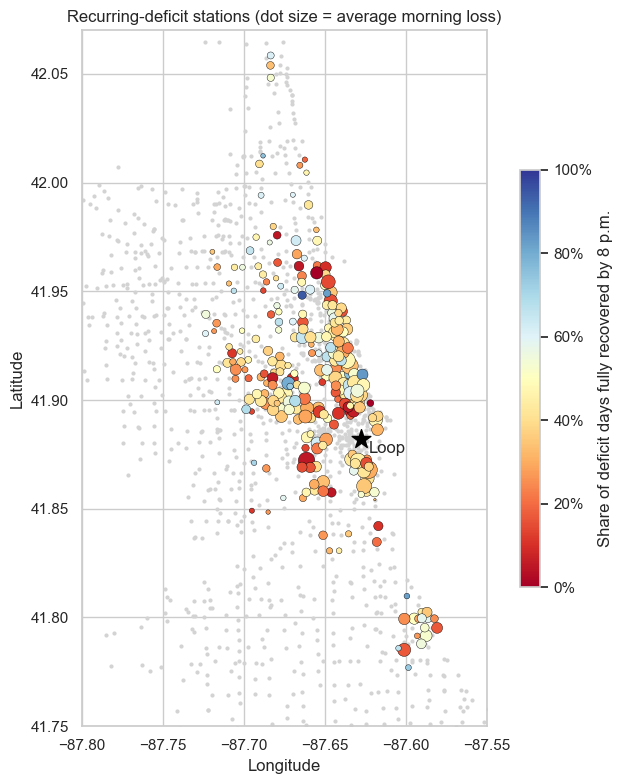

In [10]:
stations = pd.read_csv(DATA / "stations.csv")
LOOP = (41.8819, -87.6278)   # State & Madison
km_per_deg = 111
stations["km_from_loop"] = np.hypot((stations["lat"] - LOOP[0]) * km_per_deg,
                                    (stations["lng"] - LOOP[1]) * km_per_deg * np.cos(np.radians(LOOP[0])))
per_station = per_station.merge(stations[["station_id", "lat", "lng", "km_from_loop"]],
                                on="station_id", how="left", validate="one_to_one")
station_summary = station_summary.merge(stations[["station_id", "lat", "lng", "km_from_loop"]],
                                        on="station_id", how="left", validate="one_to_one")

fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(per_station["lng"], per_station["lat"], s=4, color="lightgray", label="Other weekday stations")
pts = ax.scatter(station_summary["lng"], station_summary["lat"], c=station_summary["full_recovery_rate"],
                 s=station_summary["mean_morning_net_dep"] * 12, cmap="RdYlBu", vmin=0, vmax=1,
                 edgecolor="black", linewidth=0.3)
ax.scatter(LOOP[1], LOOP[0], marker="*", s=200, color="black")
ax.annotate("Loop", (LOOP[1], LOOP[0]), xytext=(6, -10), textcoords="offset points")
ax.set_aspect(1 / np.cos(np.radians(LOOP[0])))
ax.set(xlim=(-87.80, -87.55), ylim=(41.75, 42.07))
fig.colorbar(pts, ax=ax, shrink=0.6, format=plt.FuncFormatter(lambda x, _: f"{x:.0%}"),
             label="Share of deficit days fully recovered by 8 p.m.")
ax.set(xlabel="Longitude", ylabel="Latitude",
       title="Recurring-deficit stations (dot size = average morning loss)")
fig.tight_layout()
fig.savefig(FIG / "sean_station_map.png", dpi=200)
plt.show()

In [11]:
# Recurring deficits and recovery by distance from the Loop
bands = [0, 2, 5, 10, np.inf]
band_labels = ["Under 2 km", "2–5 km", "5–10 km", "10+ km"]
per_station["distance"] = pd.cut(per_station["km_from_loop"], bands, labels=band_labels)

by_distance = per_station.groupby("distance", observed=True).agg(
    stations=("station_id", "count"),
    recurring_stations=("recurring", "sum"),
    share_recurring=("recurring", "mean"),
    mean_morning_net_dep=("mean_morning_net_dep", "mean"),
)
rec_days = rec_days.merge(per_station[["station_id", "distance"]], on="station_id", how="left", validate="many_to_one")
by_distance = by_distance.join(recovery_summary(rec_days, "distance")[["full_recovery_rate", "pooled_recovery"]])
by_distance = by_distance.round(3)
by_distance.to_csv(FIG / "sean_distance_bands.csv")
by_distance

,stations,recurring_stations,share_recurring,mean_morning_net_dep,full_recovery_rate,pooled_recovery
distance,,,,,,
Under 2 km,164,30,0.183,-3.317,0.308,0.386
2–5 km,203,89,0.438,1.540,0.411,0.726
5–10 km,445,110,0.247,0.682,0.387,0.584
10+ km,711,35,0.049,0.038,0.444,0.626


Recurring deficits are concentrated 2–5 km from the Loop, mostly to the north and northwest, with a smaller group around Hyde Park. 44% of stations at that distance are recurring-deficit stations, compared with 18% within 2 km and 5% beyond 10 km. Stations within 2 km gain bikes in the morning on average, since that's where commuters ride to. The 30 recurring-deficit stations that are that close to the Loop recover worst (39% pooled, vs 73% at 2–5 km).

## Clustering hourly flow curves (bonus)

The thirds above are an arbitrary split. As a check, k-means groups the recurring-deficit stations by the shape of their average weekday curve. Each curve is divided by the station's loss at 10 a.m., so stations are grouped by when bikes come back rather than by how many they lose.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

shape = station_curves.div(-station_curves[MORNING[1] - 1].clip(upper=-0.5), axis=0)
for k in range(2, 7):
    labels_k = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(shape)
    print(f"k={k}: silhouette {silhouette_score(shape, labels_k):.2f}")

k=2: silhouette 0.40
k=3: silhouette 0.31
k=4: silhouette 0.27
k=5: silhouette 0.25
k=6: silhouette 0.20


,stations,mean_morning_net_dep,median_full_recovery_rate,median_km_from_loop
cluster,,,,
Keeps losing after 10 a.m.,39,2.75,0.19,6.53
"Recovers slowly, by midnight",161,4.44,0.39,5.56
Recovers by early evening,64,4.01,0.57,4.54


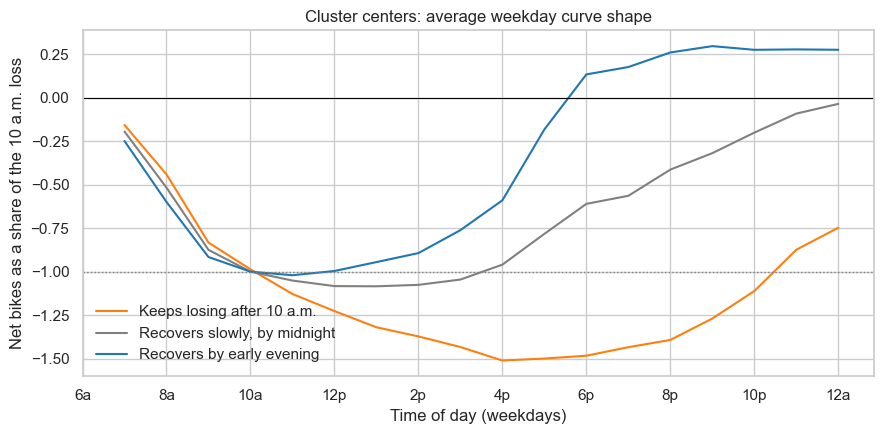

In [13]:
km = KMeans(n_clusters=3, n_init=20, random_state=0).fit(shape)
centers = pd.DataFrame(km.cluster_centers_, columns=shape.columns)

# Name clusters by where their average curve ends at midnight
order = centers[shape.columns[-1]].sort_values().index
names = dict(zip(order, ["Keeps losing after 10 a.m.", "Recovers slowly, by midnight", "Recovers by early evening"]))
clusters = pd.DataFrame({"station_id": shape.index, "cluster": pd.Series(km.labels_).map(names).values})
station_summary = station_summary.merge(clusters, on="station_id", how="left", validate="one_to_one")

cluster_order = [names[i] for i in order]
display(station_summary.groupby("cluster").agg(
    stations=("station_id", "count"),
    mean_morning_net_dep=("mean_morning_net_dep", "mean"),
    median_full_recovery_rate=("full_recovery_rate", "median"),
    median_km_from_loop=("km_from_loop", "median"),
).reindex(cluster_order).round(2))

centers_long = centers.rename(index=names).reset_index(names="cluster").melt(
    id_vars="cluster", var_name="hour", value_name="share")
centers_long["hour_end"] = centers_long["hour"].astype(int) + 1
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=centers_long, x="hour_end", y="share", hue="cluster",
             palette=["tab:orange", "gray", "tab:blue"], hue_order=cluster_order, ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(-1, color="gray", ls=":", lw=1)
ax.set_xticks([6, 8, 10, 12, 14, 16, 18, 20, 22, 24], ["6a", "8a", "10a", "12p", "2p", "4p", "6p", "8p", "10p", "12a"])
ax.set(xlabel="Time of day (weekdays)", ylabel="Net bikes as a share of the 10 a.m. loss",
       title="Cluster centers: average weekday curve shape")
ax.legend(title=None, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "sean_flow_clusters.png", dpi=200)
plt.show()

k = 2 has the highest silhouette score (0.40 vs 0.31 for k = 3), but three clusters are easier to interpret and separate out a group with a clearly different shape, so we use k = 3.

The clusters line up with recovery even though k-means never saw the recovery rates. The 64 stations that recover by early evening fully recover on a median 57% of deficit days and end the day with a small surplus. The 39 stations that keep losing after 10 a.m. fully recover on only 19% of days, are farther from the Loop (median 6.5 km), and are still short at midnight.

## Sensitivity checks

The weekday summary is recomputed using only deficits of at least 5 bikes (which avoids unstable ratios like 3 ÷ 1), a 7–9 a.m. or 6–11 a.m. morning window, and a recovery window ending at 10 p.m. or midnight.

In [14]:
weekday_events = events[events["day_type"] == "Weekday"]

def flows_for_windows(morning, later):
    e = weekday_events.copy()
    e["window"] = np.select([e["hour"].between(morning[0], morning[1] - 1), e["hour"].between(later[0], later[1] - 1)],
                            ["morning", "later"], default="other")
    e = e[e["window"] != "other"]
    e["flow"] = e["window"] + "_" + e["event"]
    f = e.pivot_table(index=["station_id", "day"], columns="flow", values="ride_id", aggfunc="count").fillna(0)
    f["morning_net_departures"] = f["morning_departure"] - f["morning_arrival"]
    f["later_net_arrivals"] = f["later_arrival"] - f["later_departure"]
    f = f[f["morning_net_departures"] > 0].reset_index()
    f["recovery"] = f["later_net_arrivals"] / f["morning_net_departures"]
    f["full_recovery"] = f["recovery"] >= 1
    return f

specs = {
    "Main (6–10a, 10a–8p)": ((6, 10), (10, 20)),
    "Morning 7–9a": ((7, 9), (9, 20)),
    "Morning 6–11a": ((6, 11), (11, 20)),
    "Recovery to 10p": ((6, 10), (10, 22)),
    "Recovery to midnight": ((6, 10), (10, 24)),
}
pieces = []
for label, (morning, later) in specs.items():
    f = flows_for_windows(morning, later)
    f["windows"] = label
    f["deficit"] = np.where(f["morning_net_departures"] >= 5, "≥ 5 bikes", "1–4 bikes")
    pieces.append(f)
all_specs = pd.concat(pieces, ignore_index=True)

any_deficit = recovery_summary(all_specs, "windows")
any_deficit.insert(0, "deficit", "any (≥ 1)")
big_deficit = recovery_summary(all_specs[all_specs["deficit"] == "≥ 5 bikes"], "windows")
big_deficit.insert(0, "deficit", "≥ 5 bikes")
sensitivity = pd.concat([any_deficit, big_deficit]).reset_index().sort_values(["windows", "deficit"])
sensitivity.to_csv(FIG / "sean_sensitivity.csv", index=False)
sensitivity

,windows,deficit,station_days,stations,median_recovery,full_recovery_rate,pooled_recovery
0,"Main (6–10a, 10a–8p)",any (≥ 1),8548,1001,0.500,0.386,0.567
5,"Main (6–10a, 10a–8p)",≥ 5 bikes,2222,315,0.571,0.282,0.554
1,Morning 6–11a,any (≥ 1),8866,1043,0.500,0.382,0.575
6,Morning 6–11a,≥ 5 bikes,2425,345,0.571,0.281,0.559
2,Morning 7–9a,any (≥ 1),7501,942,0.500,0.431,0.621
7,Morning 7–9a,≥ 5 bikes,1399,260,0.667,0.364,0.645
3,Recovery to 10p,any (≥ 1),8548,1001,0.643,0.428,0.681
8,Recovery to 10p,≥ 5 bikes,2222,315,0.714,0.352,0.676
4,Recovery to midnight,any (≥ 1),8548,1001,0.767,0.468,0.773
9,Recovery to midnight,≥ 5 bikes,2222,315,0.800,0.414,0.762


Using only deficits of at least 5 bikes barely changes the median or pooled recovery, but full recovery drops from about 39% to 28%: large losses are rarely fully replaced by 8 p.m. Extending the recovery window to midnight raises pooled recovery to about 77%, though more than half of deficit days still don't fully recover. Changing the morning window doesn't change the overall pattern.

## Summary

1. 264 stations lose bikes on at least 15 of 21 weekday mornings; most other stations rarely do.
2. At these stations, later traffic replaces about 60% of the morning loss overall, but full recovery by 8 p.m. happens on only about 40% of days.
3. Most recovery comes from the 3–6 p.m. commute. Stations that rarely recover are still short at midnight.
4. Stations with bigger typical deficits fully recover slightly less often but get back a similar or larger share of their loss.
5. Recurring deficits are concentrated 2–5 km from the Loop (44% of stations there, vs 18% within 2 km and 5% beyond 10 km), mostly to the north and northwest.
6. Clustering the daily curves gives three shapes. The 39 stations that keep losing bikes after 10 a.m. fully recover on only 19% of deficit days.

Limitations: trip data can't show whether a station actually ran empty or was restocked by truck, e-bike trips without a station aren't counted, and this is only one month.